## Notebook - Cost of Quality

In [100]:
/**********************************************************************************************
Description:
Sample:
Date      Modified By      Change Description
---------- ------------------ ------------------------------------------------------------
**********************************************************************************************/
SET TRANSACTION ISOLATION LEVEL READ UNCOMMITTED
SET DEADLOCK_PRIORITY LOW
IF OBJECT_ID('tempdb..#Results') IS NOT NULL DROP TABLE #Results
IF OBJECT_ID('tempdb..#Scrap') IS NOT NULL DROP TABLE #Scrap
IF OBJECT_ID('TEMPDB..#CteBase') IS NOT NULL DROP TABLE #CteBase

Commands completed successfully.

Total execution time: 00:00:00.009

## Scrap - Source IQM

In [101]:
select sum(isnull(reference_7,0)) 
			from [SQL-BI-1].Datawarehouse.dbo.vq_nonconformance ncms 
			join [SQL-BI-1].Datawarehouse.dbo.vq_production_order pos on ncms.PROD_ORDER_REC_ID = pos.record_id 
			where 1 =1  


(1 row affected)

(No column name)
----------------
52090.0000      
(1 row)

Total execution time: 00:00:00.196

## Scrap - Verification by Workorder
 - Note: joins by composite

In [102]:
SELECT 'Scrap' AS CLASS
	, W.BASE_ID, W.LOT_ID, W.SPLIT_ID, W.SUB_ID
	, CAST((W.ACT_MATERIAL_COST + W.ACT_LABOR_COST + W.ACT_BURDEN_COST + W.ACT_SERVICE_COST) 
             / (CASE WHEN W.DESIRED_QTY = 0 THEN 1 ELSE W.DESIRED_QTY END) AS DECIMAL(14,2)) AS UNIT_COST
	, W.PART_ID
	, CAST(W.DESIRED_QTY AS DECIMAL(14,0)) AS DESIRED_QTY
	, W.CREATE_DATE, W.CREATE_DATE AS POSTING_DATE
	, W.ACT_MATERIAL_COST + W.ACT_LABOR_COST + W.ACT_BURDEN_COST + W.ACT_SERVICE_COST AS WO_TTL_COST
	, isnull(
		(select sum(isnull(reference_7,0)) 
			from vq_nonconformance ncms 
			join vq_production_order pos on ncms.PROD_ORDER_REC_ID = pos.record_id 
			where pos.alt_id_1 = w.type and pos.alt_id_2 = w.base_id
			and pos.alt_id_3 = w.lot_id and pos.alt_id_4 = w.split_id), 0
		) AS TotalNcmScrapQty
		into #scrap
	FROM [SQL-Lab-2].live.dbo.[WORK_ORDER] W 
	JOIN [SQL-Lab-2].live.dbo.[PART] P ON W.PART_ID = P.ID AND P.TOOL_OR_FIXTURE = 'N'
	WHERE W.STATUS = 'X' AND W.SUB_ID = 0 
		AND (W.ACT_MATERIAL_COST+W.ACT_LABOR_COST+W.ACT_BURDEN_COST+W.ACT_SERVICE_COST)>0
		--AND w.CREATE_DATE >= DATEADD(DAY,1,EOMONTH( DATEADD(YEAR,-1,GETDATE()),0)) --restore in 2026
		AND w.CREATE_DATE >= '2026-01-01' AND w.CREATE_DATE <= '2026-06-30'

(658 rows affected)

Total execution time: 00:00:00.379

## Scrap dataset is only filtered by WO status X


In [103]:
select Top 35 * FROM #SCRAP

(35 rows affected)

CLASS | BASE_ID | LOT_ID | SPLIT_ID | SUB_ID | UNIT_COST | PART_ID       | DESIRED_QTY | CREATE_DATE             | POSTING_DATE            | WO_TTL_COST    | TotalNcmScrapQty
------+---------+--------+----------+--------+-----------+---------------+-------------+-------------------------+-------------------------+----------------+-----------------
Scrap | 1742122 | 1      | 4        | 0      | 231.44    | 353A4202-1    | 15          | 2026-02-26 00:00:00.000 | 2026-02-26 00:00:00.000 | 3471.66000000  | 0.0000          
Scrap | 1742122 | 1      | 5        | 0      | 310.32    | 353A4202-1    | 1           | 2026-03-11 00:00:00.000 | 2026-03-11 00:00:00.000 | 310.32000000   | 0.0000          
Scrap | 1764467 | 1      | 2        | 0      | 1137.37   | 151W7582-21   | 3           | 2026-04-07 00:00:00.000 | 2026-04-07 00:00:00.000 | 3412.11000000  | 0.0000          
Scrap | 1765413 | 1      | 1        | 0      | 161.84    | 256W6892-6    | 3           | 2026-06-08 00:00

## Query - filter for Scrap Qty > 0
- Should the 'scrap' label be chanmged, or should the code be corrected

In [104]:
select * FROM #SCRAP where isnull(TotalNcmScrapQty,0) > 0

(26 rows affected)

CLASS | BASE_ID | LOT_ID | SPLIT_ID | SUB_ID | UNIT_COST | PART_ID         | DESIRED_QTY | CREATE_DATE             | POSTING_DATE            | WO_TTL_COST    | TotalNcmScrapQty
------+---------+--------+----------+--------+-----------+-----------------+-------------+-------------------------+-------------------------+----------------+-----------------
Scrap | 1804032 | 1      | 4        | 0      | 2135.22   | 313Z7430-504    | 1           | 2026-05-26 00:00:00.000 | 2026-05-26 00:00:00.000 | 2135.22000000  | 1.0000          
Scrap | 1804662 | 1      | 0        | 0      | 712.11    | 140T2101-273    | 4           | 2026-01-02 13:48:23.217 | 2026-01-02 13:48:23.217 | 2848.43000000  | 4.0000          
Scrap | 1804836 | 1      | 0        | 0      | 263.11    | 146T5401-9200   | 3           | 2026-01-05 14:13:24.490 | 2026-01-05 14:13:24.490 | 789.32000000   | 3.0000          
Scrap | 1804996 | 1      | 0        | 0      | 319.17    | 151W7590-215-S2 | 10          | 2026

## Problem Code: Scrap is not filtered in query

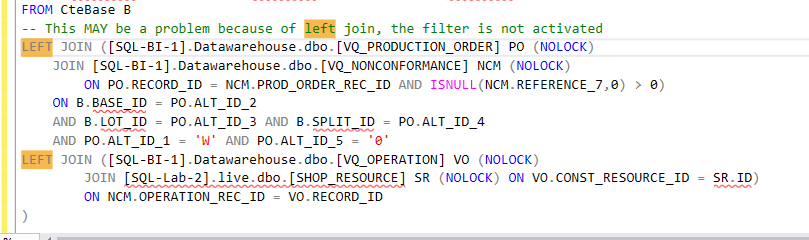

In [105]:
; WITH CteBase as 
(	SELECT 'Scrap' AS CLASS
	, W.BASE_ID, W.LOT_ID, W.SPLIT_ID, W.SUB_ID
	, CAST((W.ACT_MATERIAL_COST + W.ACT_LABOR_COST + W.ACT_BURDEN_COST + W.ACT_SERVICE_COST) 
			/ (CASE WHEN W.DESIRED_QTY = 0 THEN 1 ELSE W.DESIRED_QTY END) AS DECIMAL(14,2)) AS UNIT_COST
	, W.PART_ID
	, CAST(W.DESIRED_QTY AS DECIMAL(14,0)) AS DESIRED_QTY
	, W.CREATE_DATE, W.CREATE_DATE AS POSTING_DATE
	, W.ACT_MATERIAL_COST + W.ACT_LABOR_COST + W.ACT_BURDEN_COST + W.ACT_SERVICE_COST AS WO_TTL_COST
	, isnull(
		(select sum(isnull(reference_7,0)) 
			from [SQL-BI-1].Datawarehouse.dbo.vq_nonconformance ncms 
			join [SQL-BI-1].Datawarehouse.dbo.vq_production_order pos on ncms.PROD_ORDER_REC_ID = pos.record_id 
			where pos.alt_id_1 = w.type and pos.alt_id_2 = w.base_id
			and pos.alt_id_3 = w.lot_id and pos.alt_id_4 = w.split_id), 0
		) AS TotalNcmScrapQty
	FROM [SQL-Lab-2].live.dbo.[WORK_ORDER] W 
	JOIN [SQL-Lab-2].live.dbo.[PART] P ON W.PART_ID = P.ID AND P.TOOL_OR_FIXTURE = 'N'
	WHERE W.STATUS = 'X' AND W.SUB_ID = 0 
		AND (W.ACT_MATERIAL_COST+W.ACT_LABOR_COST+W.ACT_BURDEN_COST+W.ACT_SERVICE_COST)>0
		--AND w.CREATE_DATE >= DATEADD(DAY,1,EOMONTH( DATEADD(YEAR,-1,GETDATE()),0)) --restore in 2026
		--AND w.CREATE_DATE >= '2024-12-01'
		-- TEST
		AND w.CREATE_DATE >= '2026-01-01' AND w.CREATE_DATE <= '2026-06-30'
		UNION ALL
	/***********************         UNION With [SQL-Lab-2].[LIVEARC].[dbo].         **********************/
	SELECT 'Scrap' AS CLASS
	, W.BASE_ID, W.LOT_ID, W.SPLIT_ID, W.SUB_ID
	, CAST((W.ACT_MATERIAL_COST + W.ACT_LABOR_COST + W.ACT_BURDEN_COST + W.ACT_SERVICE_COST) / (CASE WHEN W.DESIRED_QTY = 0 THEN 1 ELSE W.DESIRED_QTY END) AS DECIMAL(14,2)) AS UNIT_COST
	, W.PART_ID
	, CAST(W.DESIRED_QTY AS DECIMAL(14,0)) AS DESIRED_QTY
	, W.CREATE_DATE, W.CREATE_DATE AS POSTING_DATE
	, W.ACT_MATERIAL_COST + W.ACT_LABOR_COST + W.ACT_BURDEN_COST + W.ACT_SERVICE_COST AS WO_TTL_COST
	, isnull(
		(select sum(isnull(reference_7,0)) 
			from [SQL-BI-1].Datawarehouse.dbo.vq_nonconformance ncms 
			join [SQL-BI-1].Datawarehouse.dbo.vq_production_order pos on ncms.PROD_ORDER_REC_ID = pos.record_id 
			where pos.alt_id_1 = w.type and pos.alt_id_2 = w.base_id
			and pos.alt_id_3 = w.lot_id and pos.alt_id_4 = w.split_id), 0
		) AS TotalNcmScrapQty
	FROM [SQL-Lab-2].[LIVEARC].[dbo].[WORK_ORDER] W 
	JOIN [SQL-Lab-2].[LIVEARC].[dbo].[PART] P ON W.PART_ID = P.ID AND P.TOOL_OR_FIXTURE = 'N'
	WHERE W.STATUS = 'X' AND W.SUB_ID = 0 
		AND (W.ACT_MATERIAL_COST+W.ACT_LABOR_COST+W.ACT_BURDEN_COST+W.ACT_SERVICE_COST)>0
		AND w.CREATE_DATE >= DATEADD(DAY,1,EOMONTH( DATEADD(YEAR,-1,GETDATE()),0)) 
		AND w.CREATE_DATE < '2024-12-01'
)
Select * into #CteBase FROM  CteBase

(658 rows affected)

Total execution time: 00:00:00.379

# Continue Test for Scrap
- In the output of the query section, notice that non-scrap is included in the dataset

In [106]:
 With Tester AS (select 1 col)
, CteBaseNCM AS 
(SELECT NCM.NCM_ID, B.CLASS, B.BASE_ID, B.LOT_ID, B.SPLIT_ID, B.PART_ID, B.UNIT_COST
	, CASE 
		WHEN NCM.REFERENCE_7 IS NULL THEN B.WO_TTL_COST
		ELSE (B.WO_TTL_COST / B.TotalNcmScrapQty) * NCM.REFERENCE_7 
	END AS OPERATIONAL_COST
	, NCM.DISPOSITION_TYPE
	, CAST(ISNULL(NCM.REFERENCE_6,0) AS DECIMAL(14,0)) AS REWORK_QTY, CAST(ISNULL(NCM.REFERENCE_7,0) AS DECIMAL(14,0)) AS SCRAP_QTY, CAST(ISNULL(NCM.REFERENCE_8,0)  AS DECIMAL(14,0)) AS OVERAGE_QTY
	, CAST(ISNULL(NCM.REFERENCE_9,0) AS DECIMAL(14,0))AS RETURN_QTY, CAST(ISNULL(NCM.REFERENCE_10,0) AS DECIMAL(14,0)) AS ASIS_QTY, CAST(ISNULL(NCM.REJECTED,B.DESIRED_QTY) AS DECIMAL(14,0)) AS REJECTED
	, CAST(ISNULL(NCM.ACCEPTED,0) AS DECIMAL(14,0)) AS ACCEPTED
	, ISNULL(NCM.SK_FIN_NCM_PROCESS,NCM.SK_MFG_NCM_PROCESS) AS PROCESS
	, ISNULL(NCM.SK_FIN_NCM_SUBPROCESS,NCM.SK_MFG_NCM_SUBPROCESS) AS SUBPROCESS
	, NCM.USER_DEFINED_3 AS CATEGORY
	, ISNULL(NCM.USER_DEFINED_4, NCM.USER_DEFINED_7) AS DEFECT
	, B.WO_TTL_COST, B.CREATE_DATE, B.POSTING_DATE, NCM.PO_NUMBER
	, NCM.LOT_SIZE, NCM.NCM_DATE, NCM.DUE_DATE AS DUE_DATE
	, NCM.DISP_DATE AS DISPOSITION_DATE, NCM.BUSINESS_UNIT_ID
	, SR.USER_5 AS FACILITY, SR.USER_4 AS SUPERVISOR, SR.USER_7 AS SUBDEPT
FROM #CteBase B 
-- This MAY be a problem because of left join, the filter is not activated
LEFT JOIN ([SQL-BI-1].Datawarehouse.dbo.[VQ_PRODUCTION_ORDER] PO (NOLOCK) 
	JOIN [SQL-BI-1].Datawarehouse.dbo.[VQ_NONCONFORMANCE] NCM (NOLOCK) 
		ON PO.RECORD_ID = NCM.PROD_ORDER_REC_ID AND ISNULL(NCM.REFERENCE_7,0) > 0)
	ON B.BASE_ID = PO.ALT_ID_2 
	AND B.LOT_ID = PO.ALT_ID_3 AND B.SPLIT_ID = PO.ALT_ID_4 
	AND PO.ALT_ID_1 = 'W' AND PO.ALT_ID_5 = '0'
LEFT JOIN ([SQL-BI-1].Datawarehouse.dbo.[VQ_OPERATION] VO (NOLOCK) 
		JOIN [SQL-Lab-2].live.dbo.[SHOP_RESOURCE] SR (NOLOCK) ON VO.CONST_RESOURCE_ID = SR.ID)
		ON NCM.OPERATION_REC_ID = VO.RECORD_ID 
) 
Select TOP 50 * FROM CteBaseNCM

(50 rows affected)

NCM_ID  | CLASS | BASE_ID | LOT_ID | SPLIT_ID | PART_ID         | UNIT_COST | OPERATIONAL_COST | DISPOSITION_TYPE | REWORK_QTY | SCRAP_QTY | OVERAGE_QTY | RETURN_QTY | ASIS_QTY | REJECTED | ACCEPTED | PROCESS      | SUBPROCESS      | CATEGORY        | DEFECT           | WO_TTL_COST    | CREATE_DATE             | POSTING_DATE            | PO_NUMBER | LOT_SIZE | NCM_DATE                | DUE_DATE                | DISPOSITION_DATE        | BUSINESS_UNIT_ID | FACILITY | SUPERVISOR          | SUBDEPT         
--------+-------+---------+--------+----------+-----------------+-----------+------------------+------------------+------------+-----------+-------------+------------+----------+----------+----------+--------------+-----------------+-----------------+------------------+----------------+-------------------------+-------------------------+-----------+----------+-------------------------+-------------------------+-------------------------+------------------+----------+

## MS SQL Notebook 9/9/2026